# Supply-Chain Operations Analysis
### Application Engineer Take-Home

**Author:** Amr Hassanein  

---

## Overview

This notebook analyses three operational datasets — **Orders**, **Inventory**, and **Shipments** — to:

1. **Define an Ontology** that links customers, orders, products, warehouses, inventory records, and shipments into a single object graph.
2. **Automate restock recommendations** using a demand-driven, carrier-adjusted model.
3. **Surface key operational insights**: carrier performance, best-selling products, and warehouse shortage risk.

## 1 · Configuration

All tuneable parameters are defined here.

In [4]:
# ┌─────────────────────────────────────────────────────────────────────────────┐
# │  CONFIG — all assumptions and parameters in one place                       │
# │  Edit here to retune the model; no other cell should contain magic numbers  │
# └─────────────────────────────────────────────────────────────────────────────┘

CONFIG = {
    # ── Carrier lead-time assumptions (days) ─────────────────────────────────
    # Rationale: Shipments.csv has no date columns, so we cannot compute actual
    # transit durations. These are business assumptions (e.g. from SLA contracts
    # or historical averages supplied by the carrier). They are used to estimate
    # expected delivery time and to weight per-product lead times in restock logic.
    "carrier_lead_times": {
        "CarrierA": 3,
        "CarrierB": 5,
        "CarrierC": 7,
    },

    # ── Demand window ─────────────────────────────────────────────────────────
    # "Last 30 days" is measured backward from MAX(order_date) in the dataset,
    # NOT from today, because the dataset ends at 2025-04-22.
    "demand_window_days": 30,

    # ── Inventory policy parameters ──────────────────────────────────────────
    # safety_stock_days: extra days of demand to hold as buffer against forecast
    #   error and supplier variability (industry default: 7–14 days).
    # review_period_days: how often restocking orders are reviewed / placed.
    #   Combined with lead time, this sets the target cycle stock.
    # restock_threshold: minimum stock level below which we *always* restock,
    #   even if the reorder-point formula wouldn't trigger (hard floor).
    "safety_stock_days": 7,
    "review_period_days": 14,
    "restock_threshold": 10,

    # ── Demand allocation strategy across warehouses ──────────────────────────
    # Orders have no warehouse_id, so we must allocate demand to warehouses that
    # stock the product. Strategy options:
    #   "even"  — split demand equally across all warehouses that carry the product.
    #             Chosen as default because it is transparent, reproducible, and
    #             does not require additional data (e.g. warehouse location or
    #             historical fulfilment weights). Analysts can swap to "proportional"
    #             once fulfilment-source data is available.
    #   "proportional" — weight by each warehouse's current stock share.
    "demand_allocation_strategy": "even",  # "even" | "proportional"

    # ── Output paths (relative to notebook location) ─────────────────────────
    "restock_csv_path": "recommended_restocks.csv",
    "chart_png_path":   "warehouse_shortage_chart.png",
}

print("CONFIG loaded:")
for k, v in CONFIG.items():
    print(f"  {k}: {v}")


CONFIG loaded:
  carrier_lead_times: {'CarrierA': 3, 'CarrierB': 5, 'CarrierC': 7}
  demand_window_days: 30
  safety_stock_days: 7
  review_period_days: 14
  restock_threshold: 10
  demand_allocation_strategy: even
  restock_csv_path: recommended_restocks.csv
  chart_png_path: warehouse_shortage_chart.png


## 2 · Data Loading

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
import math
warnings.filterwarnings("ignore")

# ── LOAD ────────────────────────────────────────────────────────────────────
DATA_DIR = "data/"   # relative path; update if running from a different cwd

orders_raw     = pd.read_csv(DATA_DIR + "Orders.csv")
inventory_raw  = pd.read_csv(DATA_DIR + "Inventory.csv")
shipments_raw  = pd.read_csv(DATA_DIR + "Shipments.csv")
# ─────────────────────────────────────────────────────────────────────────────

print(f"Loaded  orders_raw:    {orders_raw.shape}")
print(f"Loaded  inventory_raw: {inventory_raw.shape}")
print(f"Loaded  shipments_raw: {shipments_raw.shape}")


Loaded  orders_raw:    (100, 5)
Loaded  inventory_raw: (57, 3)
Loaded  shipments_raw: (80, 4)


## 3 · Data Quality & Cleaning

### Known issues and handling decisions

| Issue | Detection | Handling |
|---|---|---|
| Shipments have no date columns | Schema inspection | Use `CONFIG["carrier_lead_times"]` assumption dict; see Section 6 |
| Orders have no quantity column | Schema inspection | Treat each order as **1 unit** |
| Orders have no warehouse_id | Schema inspection | Allocate demand per `CONFIG["demand_allocation_strategy"]` (default: even split) |
| `order_date` is a string | `dtype == object` | Parse to `datetime64[ns]` |
| Canceled orders with shipments | Status cross-join | **Flag as anomaly; exclude canceled orders from sales/demand counts** |
| Pending orders with Delivered/Delayed shipments | Status cross-join | **Flag as anomaly; use shipment status as source of truth for transit; keep order in demand if not canceled** |
| Orders with no shipment | Left-join check | Flag; include in demand if not canceled (may be unfulfilled) |
| Duplicate primary keys | `.duplicated()` | Assert zero; raise if found |
| Null values | `.isnull().sum()` | Report and drop if in key fields |
| Invalid enum values | Set membership check | Report; rows with unknown status excluded from status-based logic |
| Negative stock | `stock_quantity < 0` | Flag and clamp to 0 for safety calculations |
| Orphan foreign keys | Set difference | Report; shipments without matching order excluded from product-level analysis |


In [3]:
# ─── 3.1  Deep-copy raws so LOAD cell stays rerunnable ───────────────────────
orders    = orders_raw.copy()
inventory = inventory_raw.copy()
shipments = shipments_raw.copy()

VALID_ORDER_STATUS    = {"Pending", "Shipped", "Delivered", "Canceled"}
VALID_SHIPMENT_STATUS = {"In Transit", "Delivered", "Delayed"}

issues = []  # collect human-readable findings

# ─── 3.2  Duplicate primary keys ──────────────────────────────────────────────
for df, pk, name in [
    (orders,    "order_id",    "orders"),
    (inventory, ["product_id","warehouse_id"], "inventory"),
    (shipments, "shipment_id", "shipments"),
]:
    dupes = df.duplicated(subset=pk).sum()
    if dupes:
        issues.append(f"DUPLICATE {pk} in {name}: {dupes} rows")
    else:
        issues.append(f"✓ No duplicate primary keys in {name}")

# ─── 3.3  Null checks ─────────────────────────────────────────────────────────
for df, name in [(orders,"orders"),(inventory,"inventory"),(shipments,"shipments")]:
    nulls = df.isnull().sum()
    nulls = nulls[nulls > 0]
    if not nulls.empty:
        issues.append(f"NULLS in {name}: {nulls.to_dict()}")
    else:
        issues.append(f"✓ No nulls in {name}")

# ─── 3.4  Parse order_date ────────────────────────────────────────────────────
orders["order_date"] = pd.to_datetime(orders["order_date"], format="%Y-%m-%d", errors="coerce")
bad_dates = orders["order_date"].isnull().sum()
if bad_dates:
    issues.append(f"UNPARSEABLE order_date: {bad_dates} rows (dropped)")
    orders = orders.dropna(subset=["order_date"])
else:
    issues.append("✓ All order_date values parsed successfully to datetime")

MAX_DATE = orders["order_date"].max()
issues.append(f"  Max order_date in dataset: {MAX_DATE.date()}  →  used as reference for 'last 30 days' / 'last quarter'")

# ─── 3.5  Invalid enum values ─────────────────────────────────────────────────
bad_order_status = orders[~orders["order_status"].isin(VALID_ORDER_STATUS)]
if not bad_order_status.empty:
    issues.append(f"INVALID order_status values: {bad_order_status['order_status'].unique()} ({len(bad_order_status)} rows, excluded)")
    orders = orders[orders["order_status"].isin(VALID_ORDER_STATUS)]
else:
    issues.append("✓ All order_status values are valid")

bad_ship_status = shipments[~shipments["status"].isin(VALID_SHIPMENT_STATUS)]
if not bad_ship_status.empty:
    issues.append(f"INVALID shipment status values: {bad_ship_status['status'].unique()} ({len(bad_ship_status)} rows, excluded)")
    shipments = shipments[shipments["status"].isin(VALID_SHIPMENT_STATUS)]
else:
    issues.append("✓ All shipment status values are valid")

# ─── 3.6  Negative stock ──────────────────────────────────────────────────────
neg_stock = inventory[inventory["stock_quantity"] < 0]
if not neg_stock.empty:
    issues.append(f"NEGATIVE stock_quantity: {len(neg_stock)} rows (clamped to 0)")
    inventory["stock_quantity"] = inventory["stock_quantity"].clip(lower=0)
else:
    issues.append("✓ No negative stock values")

# ─── 3.7  Orphan foreign keys ─────────────────────────────────────────────────
orphan_shipments = shipments[~shipments["order_id"].isin(orders["order_id"])]
if not orphan_shipments.empty:
    issues.append(f"ORPHAN shipment order_ids (not in orders): {len(orphan_shipments)} rows — excluded from product analysis")
    shipments = shipments[shipments["order_id"].isin(orders["order_id"])]
else:
    issues.append("✓ All shipment order_ids found in orders")

orphan_order_products = orders[~orders["product_id"].isin(inventory["product_id"])]
if not orphan_order_products.empty:
    issues.append(f"ORDER product_ids not in inventory: {len(orphan_order_products)} rows — flagged, kept")
else:
    issues.append("✓ All order product_ids found in inventory")

# ─── 3.8  Inconsistency: canceled orders WITH shipments ──────────────────────
canceled_with_ship = orders[orders["order_status"] == "Canceled"].merge(
    shipments[["order_id","shipment_id","carrier","status"]], on="order_id"
)
issues.append(f"⚠  Canceled orders with shipment records: {len(canceled_with_ship)}")
issues.append("   → Interpretation: order was canceled after shipment was created.")
issues.append("   → Treatment: EXCLUDED from demand/sales counts; shipment record retained for carrier KPI.")

# ─── 3.9  Inconsistency: pending orders whose shipment is Delivered/Delayed ──
pending_with_ship = orders[orders["order_status"] == "Pending"].merge(
    shipments[["order_id","shipment_id","carrier","status"]], on="order_id"
)
pending_mismatch = pending_with_ship[pending_with_ship["status"].isin(["Delivered","Delayed"])]
issues.append(f"⚠  Pending orders with Delivered/Delayed shipment: {len(pending_mismatch)}")
issues.append("   → Interpretation: order status not updated after shipment event (data lag).")
issues.append("   → Treatment: INCLUDED in demand counts (not canceled); shipment status used for carrier KPI.")

# ─── 3.10 Orders with NO shipment record ─────────────────────────────────────
orders_no_ship = orders[~orders["order_id"].isin(shipments["order_id"])]
breakdown_no_ship = orders_no_ship["order_status"].value_counts().to_dict()
issues.append(f"⚠  Orders with no shipment record: {len(orders_no_ship)}  {breakdown_no_ship}")
issues.append("   → Pending/Shipped without shipment: not yet fulfilled (expected).")
issues.append("   → Delivered without shipment: possible data gap; included in demand, excluded from carrier KPI.")

# ─── 3.11  Print summary ──────────────────────────────────────────────────────
print("=" * 68)
print("DATA QUALITY SUMMARY")
print("=" * 68)
for msg in issues:
    print(msg)
print("=" * 68)
print(f"\nClean dataset sizes:")
print(f"  orders:    {len(orders)}  (raw: {len(orders_raw)})")
print(f"  inventory: {len(inventory)}  (raw: {len(inventory_raw)})")
print(f"  shipments: {len(shipments)}  (raw: {len(shipments_raw)})")


DATA QUALITY SUMMARY
✓ No duplicate primary keys in orders
✓ No duplicate primary keys in inventory
✓ No duplicate primary keys in shipments
✓ No nulls in orders
✓ No nulls in inventory
✓ No nulls in shipments
✓ All order_date values parsed successfully to datetime
  Max order_date in dataset: 2025-04-22  →  used as reference for 'last 30 days' / 'last quarter'
✓ All order_status values are valid
✓ All shipment status values are valid
✓ No negative stock values
✓ All shipment order_ids found in orders
✓ All order product_ids found in inventory
⚠  Canceled orders with shipment records: 10
   → Interpretation: order was canceled after shipment was created.
   → Treatment: EXCLUDED from demand/sales counts; shipment record retained for carrier KPI.
⚠  Pending orders with Delivered/Delayed shipment: 7
   → Interpretation: order status not updated after shipment event (data lag).
   → Treatment: INCLUDED in demand counts (not canceled); shipment status used for carrier KPI.
⚠  Orders with n

In [4]:
# ─── 3.12  Anomaly detail tables ─────────────────────────────────────────────
print("\n── Canceled orders with shipment records ──")
display(canceled_with_ship[["order_id","order_status","shipment_id","carrier","status"]].reset_index(drop=True))

print("\n── Pending orders with Delivered/Delayed shipment ──")
display(pending_mismatch[["order_id","order_status","shipment_id","carrier","status"]].reset_index(drop=True))

print("\n── Orders with no shipment record ──")
display(orders_no_ship[["order_id","customer_id","product_id","order_date","order_status"]].reset_index(drop=True))



── Canceled orders with shipment records ──


,order_id,order_status,shipment_id,carrier,status
0,O0008,Canceled,S0076,CarrierB,In Transit
1,O0010,Canceled,S0065,CarrierB,Delivered
2,O0021,Canceled,S0067,CarrierB,Delivered
3,O0026,Canceled,S0075,CarrierB,Delivered
4,O0030,Canceled,S0042,CarrierC,Delivered
5,O0039,Canceled,S0054,CarrierA,Delivered
6,O0069,Canceled,S0013,CarrierB,Delivered
7,O0079,Canceled,S0009,CarrierC,In Transit
8,O0087,Canceled,S0020,CarrierA,Delivered
9,O0099,Canceled,S0062,CarrierC,Delivered



── Pending orders with Delivered/Delayed shipment ──


,order_id,order_status,shipment_id,carrier,status
0,O0020,Pending,S0040,CarrierC,Delivered
1,O0031,Pending,S0017,CarrierA,Delivered
2,O0055,Pending,S0016,CarrierC,Delayed
3,O0056,Pending,S0011,CarrierB,Delivered
4,O0063,Pending,S0032,CarrierA,Delivered
5,O0073,Pending,S0027,CarrierB,Delivered
6,O0089,Pending,S0023,CarrierC,Delivered



── Orders with no shipment record ──


,order_id,customer_id,product_id,order_date,order_status
0,O0012,C023,P001,2025-03-10,Delivered
1,O0013,C011,P007,2025-01-23,Delivered
2,O0024,C024,P001,2025-02-13,Delivered
3,O0029,C021,P007,2025-02-09,Delivered
4,O0033,C022,P002,2025-04-20,Shipped
5,O0035,C012,P016,2025-02-23,Delivered
6,O0040,C010,P003,2025-04-04,Pending
7,O0043,C016,P005,2025-03-02,Delivered
8,O0044,C015,P015,2025-03-21,Shipped
9,O0050,C025,P007,2025-02-25,Delivered


## 4 · Ontology

An ontology is a **typed graph of real-world objects and their relationships**. It lets every team — operations, finance, logistics — query the same underlying data through consistent, business-meaningful entities rather than raw join logic.

### 4.1 Object Types

#### Customer
| Attribute | Type | Constraint |
|---|---|---|
| `customer_id` | `string` | **PK**, non-null, format `C###` |

#### Order
| Attribute | Type | Constraint |
|---|---|---|
| `order_id` | `string` | **PK**, non-null, format `O####` |
| `customer_id` | `string` | **FK → Customer.customer_id**, non-null |
| `product_id` | `string` | **FK → Product.product_id**, non-null |
| `order_date` | `date` | non-null, ISO 8601 (`YYYY-MM-DD`) |
| `order_status` | `enum` | one of `{Pending, Shipped, Delivered, Canceled}` |
| `quantity` | `integer` | assumed = **1** (column absent from source data) |

#### Product
| Attribute | Type | Constraint |
|---|---|---|
| `product_id` | `string` | **PK**, non-null, format `P###` |

#### Warehouse
| Attribute | Type | Constraint |
|---|---|---|
| `warehouse_id` | `string` | **PK**, non-null, format `W##` |

#### InventoryRecord
| Attribute | Type | Constraint |
|---|---|---|
| `product_id` | `string` | **FK → Product.product_id**, composite PK |
| `warehouse_id` | `string` | **FK → Warehouse.warehouse_id**, composite PK |
| `stock_quantity` | `integer` | ≥ 0 (clamped if negative) |

#### Shipment
| Attribute | Type | Constraint |
|---|---|---|
| `shipment_id` | `string` | **PK**, non-null, format `S####` |
| `order_id` | `string` | **FK → Order.order_id**, non-null |
| `carrier` | `string` | one of `{CarrierA, CarrierB, CarrierC}` |
| `status` | `enum` | one of `{In Transit, Delivered, Delayed}` |
| `estimated_lead_days` | `float` | derived from `CONFIG["carrier_lead_times"]` (no source timestamp available) |

---

### 4.2 Object Links (Relationships)

| Link | From | Relationship | To | Cardinality |
|---|---|---|---|---|
| places | Customer | →  | Order | 1 : N |
| is for | Order | →  | Product | N : 1 |
| has | Order | →  | Shipment | 1 : 0..1 |
| stocked at | Product | ↔ via InventoryRecord | Warehouse | M : N |

---

### 4.3 Ontology Diagram

See **ontology.mmd** in this directory (or the Mermaid source below) for the ER diagram.


In [5]:
# ─── 4.4  Build ontology-aligned dataframes ──────────────────────────────────

# Add derived estimated_lead_days to shipments
shipments = shipments.copy()
shipments["estimated_lead_days"] = shipments["carrier"].map(CONFIG["carrier_lead_times"])

# Object: Customer (unique set of customers)
customers_df = pd.DataFrame({"customer_id": orders["customer_id"].unique()}).sort_values("customer_id").reset_index(drop=True)

# Object: Product
products_df = pd.DataFrame({"product_id": inventory["product_id"].unique()}).sort_values("product_id").reset_index(drop=True)

# Object: Warehouse
warehouses_df = pd.DataFrame({"warehouse_id": inventory["warehouse_id"].unique()}).sort_values("warehouse_id").reset_index(drop=True)

# Link: Customer → Order (full order view)
customer_orders = orders.merge(customers_df, on="customer_id", how="inner")

# Link: Order → Product → Warehouse (via InventoryRecord)
order_product_inventory = orders.merge(inventory, on="product_id", how="left")

# Link: Order → Shipment
order_shipments = orders.merge(
    shipments[["order_id","shipment_id","carrier","status","estimated_lead_days"]],
    on="order_id", how="left"
)

print(f"customers_df:            {customers_df.shape}")
print(f"products_df:             {products_df.shape}")
print(f"warehouses_df:           {warehouses_df.shape}")
print(f"order_shipments (join):  {order_shipments.shape}")
print(f"order_product_inventory: {order_product_inventory.shape}")

# ─── 4.5  Customer order history example ──────────────────────────────────────
example_customer = customer_orders.groupby("customer_id").size().idxmax()
print(f"\nCustomer with most orders: {example_customer}")
history = customer_orders[customer_orders["customer_id"] == example_customer].merge(
    shipments[["order_id","shipment_id","carrier","status","estimated_lead_days"]],
    on="order_id", how="left"
)[["order_id","product_id","order_date","order_status","shipment_id","carrier","status","estimated_lead_days"]]
print(f"\nOrder history for {example_customer}:")
display(history.sort_values("order_date").reset_index(drop=True))


customers_df:            (28, 1)
products_df:             (19, 1)
warehouses_df:           (3, 1)
order_shipments (join):  (100, 9)
order_product_inventory: (300, 7)

Customer with most orders: C004

Order history for C004:


,order_id,product_id,order_date,order_status,shipment_id,carrier,status,estimated_lead_days
0,O0081,P003,2025-01-29,Delivered,S0047,CarrierB,Delivered,5.0
1,O0089,P010,2025-02-02,Pending,S0023,CarrierC,Delivered,7.0
2,O0017,P008,2025-02-14,Delivered,S0041,CarrierA,Delayed,3.0
3,O0059,P004,2025-02-22,Pending,S0044,CarrierA,In Transit,3.0
4,O0097,P002,2025-03-06,Delivered,S0006,CarrierC,Delivered,7.0
5,O0084,P008,2025-04-05,Delivered,NaN,NaN,NaN,NaN


## 5 · Task 2 — Restock Automation

### Logic overview

1. **Demand window** — count non-canceled orders in the last `demand_window_days` days (relative to `MAX_DATE`).  
2. **Daily demand per product** — `order_count / demand_window_days`.  
3. **Warehouse demand allocation** — split daily demand across warehouses per `CONFIG["demand_allocation_strategy"]`:  
   - `"even"`: each warehouse gets `daily_demand / num_warehouses_stocking_product`  
   - `"proportional"`: weight by current stock share  
4. **Lead time per product** — demand-weighted average of `CONFIG["carrier_lead_times"]` for carriers that shipped this product; falls back to overall average if product has no shipment history.  
5. **Reorder point** — `daily_demand_wh × lead_time + safety_stock_days × daily_demand_wh`  
6. **Trigger restock when**: `current_stock < reorder_point` **OR** `current_stock == 0` **OR** `current_stock < restock_threshold`  
7. **Recommended quantity** — `ceil(target_stock - current_stock)` where `target_stock = daily_demand_wh × (lead_time + review_period) + safety_stock_days × daily_demand_wh`; minimum 0.


In [6]:
def recommend_restocks(orders_df, inventory_df, shipments_df, config):
    """
    Generate restock recommendations for every warehouse/product combination.

    Parameters
    ----------
    orders_df : pd.DataFrame
        Clean orders with columns [order_id, product_id, order_date, order_status].
    inventory_df : pd.DataFrame
        Clean inventory with columns [product_id, warehouse_id, stock_quantity].
    shipments_df : pd.DataFrame
        Clean shipments with columns [order_id, carrier, status, estimated_lead_days].
    config : dict
        CONFIG dict containing demand_window_days, safety_stock_days,
        review_period_days, restock_threshold, demand_allocation_strategy,
        carrier_lead_times.

    Returns
    -------
    pd.DataFrame
        One row per (product_id, warehouse_id) that triggers a restock,
        sorted by urgency (stock_coverage_days ascending).
        Columns: product_id, warehouse_id, current_stock, daily_demand_wh,
                 lead_time_days, safety_stock, reorder_point, target_stock,
                 recommended_restock_quantity, reason, stock_coverage_days.
    """
    demand_window  = config["demand_window_days"]
    safety_days    = config["safety_stock_days"]
    review_period  = config["review_period_days"]
    threshold      = config["restock_threshold"]
    alloc_strategy = config["demand_allocation_strategy"]
    carrier_lt     = config["carrier_lead_times"]

    # ── Step 1: demand in the last N days (non-canceled) ─────────────────────
    max_date    = orders_df["order_date"].max()
    window_start = max_date - pd.Timedelta(days=demand_window)
    recent = orders_df[
        (orders_df["order_date"] > window_start) &
        (orders_df["order_status"] != "Canceled")
    ]
    # Each order = 1 unit
    product_demand = recent.groupby("product_id").size().rename("units_sold").reset_index()
    product_demand["daily_demand"] = product_demand["units_sold"] / demand_window

    # ── Step 2: per-product lead time (demand-weighted across carriers) ───────
    order_carrier = orders_df[["order_id","product_id"]].merge(
        shipments_df[["order_id","carrier","estimated_lead_days"]], on="order_id", how="inner"
    )
    # Weight by units (each row = 1 unit)
    prod_lead = (
        order_carrier.groupby(["product_id","carrier"])
        .size().rename("n").reset_index()
    )
    prod_lead["lead_days"] = prod_lead["carrier"].map(carrier_lt)
    prod_lead_wt = (
        prod_lead.groupby("product_id")
        .apply(lambda g: np.average(g["lead_days"], weights=g["n"]), include_groups=False)
        .rename("lead_time_days")
        .reset_index()
    )
    overall_avg_lead = np.average(
        list(carrier_lt.values()),
        weights=[shipments_df["carrier"].eq(c).sum() for c in carrier_lt]
    )

    # ── Step 3: warehouses that stock each product ────────────────────────────
    wh_per_product = inventory_df.groupby("product_id")["warehouse_id"].count().rename("n_warehouses").reset_index()

    # ── Step 4: build base rows = all (product_id, warehouse_id) combos ──────
    base = inventory_df[["product_id","warehouse_id","stock_quantity"]].rename(
        columns={"stock_quantity": "current_stock"}
    ).copy()

    # Merge demand and warehouse count
    base = base.merge(product_demand[["product_id","daily_demand"]], on="product_id", how="left")
    base["daily_demand"] = base["daily_demand"].fillna(0)
    base = base.merge(wh_per_product, on="product_id", how="left")

    # Merge per-product lead time (fallback to overall average)
    base = base.merge(prod_lead_wt, on="product_id", how="left")
    base["lead_time_days"] = base["lead_time_days"].fillna(overall_avg_lead)

    # ── Step 5: allocate daily demand to each warehouse ───────────────────────
    if alloc_strategy == "even":
        base["daily_demand_wh"] = base["daily_demand"] / base["n_warehouses"]
    elif alloc_strategy == "proportional":
        total_stock = base.groupby("product_id")["current_stock"].transform("sum")
        stock_share = base["current_stock"] / total_stock.replace(0, 1)
        base["daily_demand_wh"] = base["daily_demand"] * stock_share
    else:
        raise ValueError(f"Unknown demand_allocation_strategy: {alloc_strategy!r}")

    # ── Step 6: reorder point and target stock ────────────────────────────────
    base["safety_stock"]   = base["daily_demand_wh"] * safety_days
    base["reorder_point"]  = base["daily_demand_wh"] * base["lead_time_days"] + base["safety_stock"]
    # Effective target = max(formula target, restock_threshold) so that
    # threshold-triggered slow movers always get restocked to at least the floor.
    base["target_stock"]   = (
        base["daily_demand_wh"] * (base["lead_time_days"] + review_period) + base["safety_stock"]
    ).clip(lower=threshold)

    # ── Step 7: trigger logic ─────────────────────────────────────────────────
    below_rop       = base["current_stock"] < base["reorder_point"]
    zero_stock      = base["current_stock"] == 0
    below_threshold = base["current_stock"] < threshold

    def build_reason(row):
        reasons = []
        if row["current_stock"] == 0:
            reasons.append("zero stock")
        elif row["current_stock"] < threshold:
            reasons.append(f"below min threshold ({threshold})")
        if row["current_stock"] < row["reorder_point"]:
            reasons.append(f"below reorder point ({row['reorder_point']:.1f})")
        return "; ".join(reasons) if reasons else "ok"

    base["trigger"]  = below_rop | zero_stock | below_threshold
    base["reason"]   = base.apply(build_reason, axis=1)

    # ── Step 8: recommended quantity ─────────────────────────────────────────
    base["recommended_restock_quantity"] = (
        (base["target_stock"] - base["current_stock"]).clip(lower=0).apply(math.ceil)
    )
    # Zero out non-triggered rows
    base.loc[~base["trigger"], "recommended_restock_quantity"] = 0

    # ── Step 9: urgency sort key ──────────────────────────────────────────────
    base["stock_coverage_days"] = np.where(
        base["daily_demand_wh"] > 0,
        base["current_stock"] / base["daily_demand_wh"],
        np.inf
    )

    triggered = base[base["trigger"]].copy()
    triggered = triggered.sort_values("stock_coverage_days").reset_index(drop=True)

    result = triggered[[
        "product_id", "warehouse_id", "current_stock", "daily_demand_wh",
        "lead_time_days", "safety_stock", "reorder_point", "target_stock",
        "recommended_restock_quantity", "reason", "stock_coverage_days"
    ]].round(2)

    return result


# ─── Run and display ──────────────────────────────────────────────────────────
restock_df = recommend_restocks(orders, inventory, shipments, CONFIG)

print(f"Restock recommendations: {len(restock_df)} warehouse/product pairs triggered")
print()
display(restock_df)

# Save to CSV
restock_df.to_csv(CONFIG["restock_csv_path"], index=False)
print(f"\nSaved to {CONFIG['restock_csv_path']}")


Restock recommendations: 6 warehouse/product pairs triggered



,product_id,warehouse_id,current_stock,daily_demand_wh,lead_time_days,safety_stock,reorder_point,target_stock,recommended_restock_quantity,reason,stock_coverage_days
0,P002,W01,0,0.01,6.0,0.08,0.14,10.0,10,zero stock; below reorder point (0.1),0.0
1,P016,W03,0,0.01,7.0,0.08,0.16,10.0,10,zero stock; below reorder point (0.2),0.0
2,P013,W02,9,0.02,5.0,0.16,0.27,10.0,1,below min threshold (10),405.0
3,P015,W02,9,0.02,3.8,0.16,0.24,10.0,1,below min threshold (10),405.0
4,P017,W02,3,0.00,6.0,0.00,0.00,10.0,7,below min threshold (10),inf
5,P018,W03,1,0.00,5.0,0.00,0.00,10.0,9,below min threshold (10),inf



Saved to recommended_restocks.csv


## 6 · Task 3 — Operational Insights

### Data-window notes
- **"Last 30 days"**: `2025-03-23` → `2025-04-22` (30 days back from max order date).  
- **"Last quarter"**: **Q1 2025** (January 1 – March 31). This is the last *complete* calendar quarter in the dataset. Q2 2025 is only partially covered (April), so it is excluded from the quarter-based analysis.


In [7]:
# ─── 6.1  Carrier performance ────────────────────────────────────────────────
carrier_lt = CONFIG["carrier_lead_times"]

carrier_stats = (
    shipments.groupby("carrier")["status"]
    .value_counts(normalize=True)
    .mul(100).round(1)
    .unstack(fill_value=0)
    .reset_index()
)

# Ensure all status columns exist
for col in ["Delivered", "In Transit", "Delayed"]:
    if col not in carrier_stats.columns:
        carrier_stats[col] = 0.0

carrier_stats["avg_lead_days_assumption"] = carrier_stats["carrier"].map(carrier_lt)
carrier_stats = carrier_stats[["carrier","avg_lead_days_assumption","Delivered","In Transit","Delayed"]]
carrier_stats.columns = ["Carrier","Avg Lead Days (assumed)","On-Time % (Delivered)","In Transit %","Delayed %"]

print("── Carrier Performance Summary ──")
display(carrier_stats)

# ─── 6.2  Top 5 products — Q1 2025 (last complete quarter) ──────────────────
Q1_START = pd.Timestamp("2025-01-01")
Q1_END   = pd.Timestamp("2025-03-31")

q1_orders = orders[
    (orders["order_date"] >= Q1_START) &
    (orders["order_date"] <= Q1_END) &
    (orders["order_status"] != "Canceled")
]
top5 = (
    q1_orders.groupby("product_id").size()
    .rename("units_sold_Q1").sort_values(ascending=False)
    .head(5).reset_index()
)
top5.index += 1
print("\n── Top 5 Best-Selling Products — Q1 2025 (Jan 1 – Mar 31) ──")
display(top5)


── Carrier Performance Summary ──


,Carrier,Avg Lead Days (assumed),On-Time % (Delivered),In Transit %,Delayed %
0,CarrierA,3,75.8,12.1,12.1
1,CarrierB,5,76.9,11.5,11.5
2,CarrierC,7,76.2,19.0,4.8



── Top 5 Best-Selling Products — Q1 2025 (Jan 1 – Mar 31) ──


,product_id,units_sold_Q1
1,P001,6
2,P012,6
3,P003,5
4,P015,5
5,P007,5


── Warehouse Stock vs 30-Day Projected Demand ──


,warehouse_id,current_stock,projected_demand,shortage,surplus,shortfall_flag
0,W01,1076,10.333333,0.0,1065.666667,False
1,W02,981,10.333333,0.0,970.666667,False
2,W03,1075,10.333333,0.0,1064.666667,False


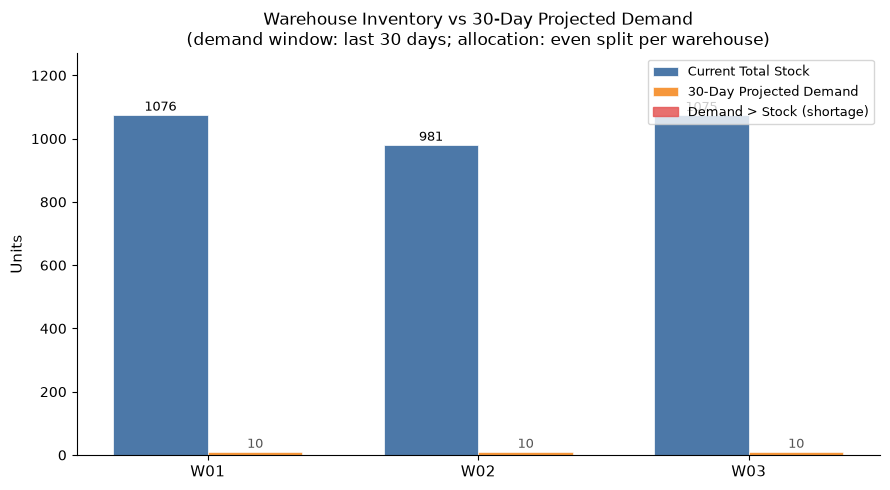

Chart saved to warehouse_shortage_chart.png


In [8]:
# ─── 6.3  Warehouse shortage chart ───────────────────────────────────────────
# Build per-warehouse current stock vs projected 30-day demand

demand_window  = CONFIG["demand_window_days"]
safety_days    = CONFIG["safety_stock_days"]
review_period  = CONFIG["review_period_days"]
carrier_lt     = CONFIG["carrier_lead_times"]

max_date     = orders["order_date"].max()
window_start = max_date - pd.Timedelta(days=demand_window)

recent_noncanceled = orders[
    (orders["order_date"] > window_start) &
    (orders["order_status"] != "Canceled")
]
product_demand = (
    recent_noncanceled.groupby("product_id").size().rename("units_sold") / demand_window
).rename("daily_demand").reset_index()

# Merge into inventory
wh_demand = inventory.merge(product_demand, on="product_id", how="left")
wh_demand["daily_demand"] = wh_demand["daily_demand"].fillna(0)

# Even split across warehouses
n_wh = wh_demand.groupby("product_id")["warehouse_id"].count().rename("n_wh")
wh_demand = wh_demand.merge(n_wh, on="product_id")
wh_demand["daily_demand_wh"] = wh_demand["daily_demand"] / wh_demand["n_wh"]
wh_demand["projected_30d_demand"] = wh_demand["daily_demand_wh"] * demand_window

# Aggregate by warehouse
wh_summary = wh_demand.groupby("warehouse_id").agg(
    current_stock=("stock_quantity", "sum"),
    projected_demand=("projected_30d_demand", "sum"),
).reset_index()
wh_summary["shortage"] = (wh_summary["projected_demand"] - wh_summary["current_stock"]).clip(lower=0)
wh_summary["surplus"]  = (wh_summary["current_stock"] - wh_summary["projected_demand"]).clip(lower=0)
wh_summary["shortfall_flag"] = wh_summary["shortage"] > 0

print("── Warehouse Stock vs 30-Day Projected Demand ──")
display(wh_summary)

# ─── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5))

warehouses  = wh_summary["warehouse_id"].tolist()
x           = np.arange(len(warehouses))
bar_width   = 0.35

bars_stock  = ax.bar(x - bar_width/2, wh_summary["current_stock"],
                     width=bar_width, label="Current Total Stock",
                     color="#4C78A8", edgecolor="white", linewidth=0.5)
bars_demand = ax.bar(x + bar_width/2, wh_summary["projected_demand"],
                     width=bar_width, label="30-Day Projected Demand",
                     color="#F58518", edgecolor="white", linewidth=0.5, alpha=0.85)

# Highlight shortage bars in red
for i, (_, row) in enumerate(wh_summary.iterrows()):
    if row["shortfall_flag"]:
        ax.bar(x[i] + bar_width/2, row["projected_demand"],
               width=bar_width, color="#E45756", alpha=0.85,
               edgecolor="white", linewidth=0.5, label="_nolegend_")

# Annotations
for i, (_, row) in enumerate(wh_summary.iterrows()):
    ax.text(x[i] - bar_width/2, row["current_stock"] + 3,
            f"{row['current_stock']:.0f}", ha="center", va="bottom", fontsize=9)
    ax.text(x[i] + bar_width/2, row["projected_demand"] + 3,
            f"{row['projected_demand']:.0f}", ha="center", va="bottom", fontsize=9, color="#E45756" if row["shortfall_flag"] else "#555")

# Legend + formatting
shortage_patch = mpatches.Patch(color="#E45756", alpha=0.85, label="Demand > Stock (shortage)")
handles, labels = ax.get_legend_handles_labels()
handles.append(shortage_patch)
ax.legend(handles=handles, loc="upper right", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(warehouses, fontsize=11)
ax.set_ylabel("Units", fontsize=11)
ax.set_title("Warehouse Inventory vs 30-Day Projected Demand\n(demand window: last 30 days; allocation: even split per warehouse)", fontsize=12)
ax.spines[["top","right"]].set_visible(False)
ax.set_ylim(0, max(wh_summary["current_stock"].max(), wh_summary["projected_demand"].max()) * 1.18)

plt.tight_layout()
plt.savefig(CONFIG["chart_png_path"], dpi=150, bbox_inches="tight")
plt.show()
print(f"Chart saved to {CONFIG['chart_png_path']}")


## 7 · Key Questions

### (a) How does the ontology enable cross-functional use of data?

The ontology turns six isolated tables into a **traversable object graph**. Consider a concrete cross-functional workflow:

- **Logistics** queries `Shipment.status = "Delayed"` → traverses `Shipment → Order → Product → InventoryRecord` to immediately see which warehouses and products are at risk of a stockout because their inbound shipment is late.
- **Demand Planning** follows `Order → Product` to compute trailing demand, then traverses `Product → InventoryRecord → Warehouse` to compare demand against current stock *per location*, driving the reorder-point logic in Section 5.
- **Customer Experience** traverses `Customer → Order → Shipment` to answer "where is my order?" without joining raw tables, since each link is pre-defined and indexed in the ontology.
- **Finance** sums `Order.quantity` (currently 1 per order) across `Customer` segments, or computes carrier cost exposure by linking `Shipment.carrier → Order.product_id → Product`.

Because the ontology is **shared infrastructure**, every downstream app, pipeline, or workshop widget queries the same object types with consistent semantics — a change to how "Delivered" is defined propagates everywhere automatically.

---

### (b) How does the automation reduce manual workload?

| Before automation | After automation |
|---|---|
| Analyst manually compares stock list to a spreadsheet of recent orders | `recommend_restocks()` runs on-demand or on schedule, scanning all 57 product/warehouse pairs in seconds |
| Carrier lead times buried in email/contracts | All assumptions live in `CONFIG["carrier_lead_times"]`; one edit, one rerun |
| Reorder point recalculated differently by each team | Single, auditable formula: `daily_demand × lead_time + safety_stock` |
| "Who decides how much to order?" answered in meetings | `recommended_restock_quantity` is a deterministic output; humans review, not derive |
| Urgency is subjective | `stock_coverage_days` provides an objective sort key — zero-stock items always surface first |

The function is idempotent and parameterised: planners can run weekly scenarios (e.g. increase `safety_stock_days` before a peak season) in seconds, eliminating the manual rebuild cycle entirely.


## 8 · Optional — Proposed Ontology Enhancements

The current ontology is limited by absent data. Below are high-value additions that would unlock significantly richer analytics.

### New Object Types

#### Supplier
| Attribute | Why it matters |
|---|---|
| `supplier_id` (PK) | Link products to their suppliers |
| `product_id` (FK) | Know which supplier provides which SKU |
| `contracted_lead_days` | Replace assumption dict with source-of-truth lead times |
| `reliability_score` | Factor variability into safety stock formula |
| `contact_info` | Trigger automated POs |

#### CarrierContract
| Attribute | Why it matters |
|---|---|
| `carrier` (PK) | Formal object vs string in Shipment |
| `sla_days` | Replace `CONFIG["carrier_lead_times"]` with structured SLAs |
| `cost_per_unit` | Model fulfilment cost per route |

### New Attributes on Existing Objects

| Object | New Attribute | Benefit |
|---|---|---|
| **Shipment** | `shipped_at`, `delivered_at` | Compute actual vs SLA transit time; no more assumptions |
| **Shipment** | `origin_warehouse_id` | Know which warehouse fulfilled each order; enable fulfilment routing |
| **Order** | `quantity` | Correct demand computation (currently forced to 1) |
| **InventoryRecord** | `reorder_point`, `reorder_quantity` | Store policy in ontology so it is visible to all apps |
| **Product** | `unit_cost`, `unit_price` | Enable margin analysis and economic order quantity (EOQ) |
| **Warehouse** | `region`, `lat`, `lon` | Route-aware demand allocation; proximity-based fulfilment |
| **Customer** | `region`, `tier` | Segment-level demand forecasting; SLA prioritisation |

### New Links

| Link | Benefit |
|---|---|
| Shipment → Warehouse (origin) | Inventory depletion traceability |
| Order → Supplier (via Product) | Procurement trigger automation |
| InventoryRecord → Supplier | Direct reorder workflow |

### Impact on the Restock Model

With `Shipment.shipped_at` and `Shipment.delivered_at`, lead times become **observed distributions** (mean ± σ per carrier × route), enabling probabilistic safety stock:
```
safety_stock = z_score × σ_lead_time × daily_demand
```
where `z_score` is set by a target service level (e.g. 1.65 for 95%).  
This removes the last assumption from the model and makes `CONFIG["carrier_lead_times"]` obsolete.
